In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import umap
from sklearn.datasets import load_digits


import hdbscan
import sklearn.cluster as cluster
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score


In [2]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [3]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

#list_affil = pd.read_csv("../list_affiliation.csv", sep =",")
df0 = df0.loc[~df0.q45_clé.isin(["9EAP-NB4B","QNYZ-3MH2"])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left")

In [13]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [4]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column]= df0.apply(lambda row: row[column].replace(";","|") ,1 )
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [5]:
for x in df0.columns:
    print(x)

qno_obs
q1_so_principles
q2_hal_depot
q3_octavi_depot
q4_diff_data
q4_autres_entrepots
q5_r
q5_python
q5_excel
q5_julia
q5_stata
q5_sas
q5_aucun
q5_autre
q5_1_other_lang
q6_dev_code
q6_1_dev_exemple
q7_software_depot
q7_1_other_sw_depot
q8_depot_hal_help
q8_rediger_pdg_help
q8_respect_rgpd_help
q8_licences_help
q8_depot_donnees_help
q8_metadonnees_help
q8_data_paper_help
q8_fair_data_help
q9_utilite_accomp
q10_type_data
q10_other_type_data
q11_quali_or_quanti
q12_humanum
q12_1_how_humanum
q13_nakala
q13_isidore
q13_sharedocs
q13_hébergement_web
q14_stylo
q14_mattermost
q14_gitlab
q14_matomo
q14_hnurl
q14_kanboard
q15_nakala_help
q15_isidore_help
q15_sharedocs_help
q15_hébergement_web_help
q15_stylo_help
q15_mattermost_help
q15_gitlab_help
q15_matomo_help
q15_hnurl_help
q15_kanboard_help
53. Tableur
54. Logiciels d'analyse statistique (ex. R – Rstudio)
55. Python (web-scraping, traitement automatique des langues…)
56. Logiciels d'exploration de textes, analyse, statistique... (ex. Garga

In [6]:
df0.loc[df0.q3_octavi_depot=="Non","octavi_depot_rec"]= "Non"
df0.loc[df0.q3_octavi_depot.str.contains("ne connais pas"),"octavi_depot_rec"]= "Ne connait pas"
df0.loc[(df0.q3_octavi_depot!="Non") & (~df0.q3_octavi_depot.str.contains("ne connais pas")),"octavi_depot_rec"]= "Oui"


In [7]:
tool_diff_data = {
    'OSF':'OSF',
    'github':'dépot git',
    'osf':'OSF',
    'Sur OSF':'OSF',
    'oui, sur des sites personnels':"site personnel",
    "Oui, au cdsp dans le cadre d'un projet ANR":"CDSP", 
    'dépot GIT':'dépot git',
    'sur mes sites personnels':"site personnel",
    'ORTOLANG, COCOON, dev perso':"Ortolang|Coccon|site personnel",
    'Serveur géré par une fondation de recherche':"Fondation de recherche",
    'Sur mon site internet':"site personnel", 
    'cela ne me concerne pas':"pas concerné",
    'Sur ma page web':"site personnel",
    'directement sur le site de soumission des articles':"Editeur", 
    'Ortolang':"Ortolang",
    'page  ou transmission personnelle':"site personnel|pair à pair",
    "Sur Nakala mais par l'intermédiaire d'un collègue":"Nakala",
    'Mendeley data':"Mendeley data"
}

type_entrepot = {
    'OSF':'Autre entrepot',
    'github':'page personnelle',
    'osf':'Autre entrepot',
    'Sur OSF':'Autre entrepot',
    'oui, sur des sites personnels':"page personnelle",
    "Oui, au cdsp dans le cadre d'un projet ANR":"Entrepot institutionnel", 
    'dépot GIT':'page personnelle',
    'sur mes sites personnels':"page personnelle",
    'ORTOLANG, COCOON, dev perso':"Entrepot institutionnel|page personnelle",
    'Serveur géré par une fondation de recherche':"Autre entrepot",
    'Sur mon site internet':"page personnelle", 
    'cela ne me concerne pas':"pas concerné",
    'Sur ma page web':"page personnelle",
    'directement sur le site de soumission des articles':"Editeur", 
    'Ortolang':"Entrepot institutionnel",
    'page  ou transmission personnelle':"page personnelle|pair à pair",
    "Sur Nakala mais par l'intermédiaire d'un collègue":"Entrepot institutionnel",
    'Mendeley data':"Autre entrepot"
}

In [8]:
df0["q4_autres_entrepots_rec"] = df0.q4_autres_entrepots.map(tool_diff_data)


In [9]:
df0["type_entrepot"] = df0.q4_autres_entrepots.map(type_entrepot.get)
df0.q4_diff_data.unique()

type_entrepot2 = {'Non':'Non', 
                  'Autre, précisez':'Autre, précisez', 
                  'Oui, sur Zenodo, Nakala':'Autre entrepot',
                  'Oui, sur Data Paris 8':'Entrepot institutionnel', 
                  'Oui, sur Nakala':'Entrepot institutionnel',
                  'Non;Oui, sur Nakala':'Entrepot institutionnel'}
df0["type_entrepot1"] = df0.q4_diff_data.map(type_entrepot2.get)

In [10]:
list_key=[]
for key in df0.q45_clé:
    diff_data = df0.type_entrepot1.loc[df0.q45_clé==key].iloc[0]
    autre = df0.type_entrepot.loc[df0.q45_clé==key].iloc[0]
    #print(type(autre))
    if 'entrepot' in diff_data:
        depot_entrepot = "Oui"
    else:
        if type(autre)== str:
            if 'entrepot' in autre:
                depot_entrepot = "Oui"
            else:
                depot_entrepot = "Non"
        else:
            depot_entrepot = "Non"
    dict_key={"q45_clé":key,
              "depot_entrepot":depot_entrepot}
    list_key.append(dict_key)
df_key = pd.DataFrame.from_dict(list_key)
df0 = df0.merge(df_key, on =["q45_clé"], how ="left")

In [23]:
df0.groupby("depot_entrepot").agg(nb = ("q45_clé","size"))
df1 = df0.loc[df0.q4_diff_data!="Non"]
tab_croise = pd.crosstab(df1.depot_entrepot, df1.q25_statut_rec, margins=True).sort_values("depot_entrepot")
print(tab_croise.to_markdown())

| depot_entrepot   |   Chercheur |   Doctorant |   Personnel d'appui à la recherche |   All |
|:-----------------|------------:|------------:|-----------------------------------:|------:|
| All              |          31 |           1 |                                  3 |    35 |
| Non              |          16 |           0 |                                  3 |    19 |
| Oui              |          15 |           1 |                                  0 |    16 |


In [27]:
df0.loc[df0.q4_diff_data !="Non", "q4_diff_data_grouped"] = "Oui"
df0.loc[df0.q4_diff_data =="Non", "q4_diff_data_grouped"] = "Non"
tab_croise = pd.crosstab(df0.q4_diff_data_grouped, df0.q25_statut_rec, margins=True)
print(tab_croise.to_markdown())

| q4_diff_data_grouped   |   Chercheur |   Doctorant |   Personnel d'appui à la recherche |   All |
|:-----------------------|------------:|------------:|-----------------------------------:|------:|
| Non                    |          73 |          11 |                                  0 |    84 |
| Oui                    |          31 |           1 |                                  3 |    35 |
| All                    |         104 |          12 |                                  3 |   119 |


In [228]:
var_os = ["q45_clé","q1_so_principles","q2_hal_depot","octavi_depot_rec","depot_entrepot"]
df_os = df0[var_os].set_index("q45_clé")

In [229]:
for col in df_os.columns:
    df_os[col] = df_os.apply(lambda row: f'{col.split("_")[0]}_{str(row[col])}', 1) # lower sentence

In [230]:
df_os

,q1_so_principles,q2_hal_depot,octavi_depot_rec,depot_entrepot
q45_clé,,,,
GNEG-5QXQ,"q1_Oui, un peu","q2_Oui, une fois",octavi_Non,depot_Non
FCCB-GMYA,"q1_Oui, tout à fait","q2_Oui, plusieurs fois",octavi_Ne connait pas,depot_Non
CV3G-95CT,"q1_Oui, un peu","q2_Oui, une fois",octavi_Non,depot_Oui
M5L8-UM9F,"q1_Oui, un peu","q2_Oui, systématiquement",octavi_Ne connait pas,depot_Non
HT8V-PSKZ,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Non
...,...,...,...,...
MLSN-NBUS,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Oui
WAR9-LFJP,"q1_Oui, un peu","q2_Oui, systématiquement",octavi_Non,depot_Non
HRZG-6JGE,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Non


In [54]:
!pip install fanalysis

In [55]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [56]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [57]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [234]:
#récupération des variables actives
DActives = df_os.copy()
#print(DActives)

#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]

4
4 117


In [235]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[  0.43993838,  21.99691903,  21.99691903],
       [  0.30377673,  15.18883643,  37.18575547],
       [  0.25605185,  12.80259232,  49.98834778],
       [  0.2521518 ,  12.60758986,  62.59593764],
       [  0.2242374 ,  11.21186991,  73.80780756],
       [  0.21076473,  10.53823651,  84.34604407],
       [  0.17594938,   8.79746882,  93.14351289],
       [  0.13712974,   6.85648711, 100.        ]])

In [237]:
#nombre max de facteurs
Hmax = M-p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

12 8


,Val_P,%,Cumul %
1,0.439938,21.996919,21.996919
2,0.303777,15.188836,37.185755
3,0.256052,12.802592,49.988348
4,0.252152,12.607590,62.595938
5,0.224237,11.211870,73.807808
6,0.210765,10.538237,84.346044
7,0.175949,8.797469,93.143513
8,0.137130,6.856487,100.000000


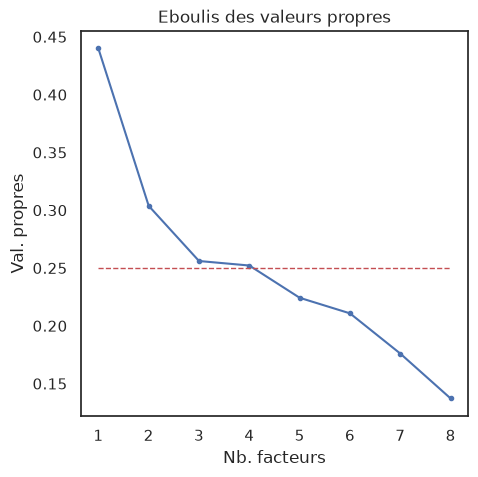

In [238]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

In [244]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.43993838 0.30377673 0.25605185 0.2521518 ]
[6.41361572e-02 5.14122053e-03 6.51108349e-05 8.23152209e-06]
0.06935072010508446


In [246]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,5)))


      Val.P          %     Cumul %
1  0.064136  92.480881   92.480881
2  0.005141   7.413363   99.894244
3  0.000065   0.093886   99.988131
4  0.000008   0.011869  100.000000


In [248]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,5)))

0.0792481173966298
      Val.P         %   Cumul %
1  0.064136  0.809308  0.809308
2  0.005141  0.064875  0.874183
3  0.000065  0.000822  0.875005
4  0.000008  0.000104  0.875109


In [252]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

                          Coord.F1  Coord.F2
q1_Non                    1.074868  1.954655
q1_Oui, tout à fait      -1.025953  0.186864
q1_Oui, un peu            0.368278 -0.530246
q2_Non                    1.270100  1.164383
q2_Oui, plusieurs fois    0.041962 -0.787284
q2_Oui, systématiquement -0.791980  0.281504
q2_Oui, une fois          0.905402  0.710471
octavi_Ne connait pas    -1.030077  0.345607
octavi_Non                0.294676 -0.107685
octavi_Oui                0.171195  0.007484
depot_Non                 0.252689 -0.090893
depot_Oui                -1.595097  0.573764


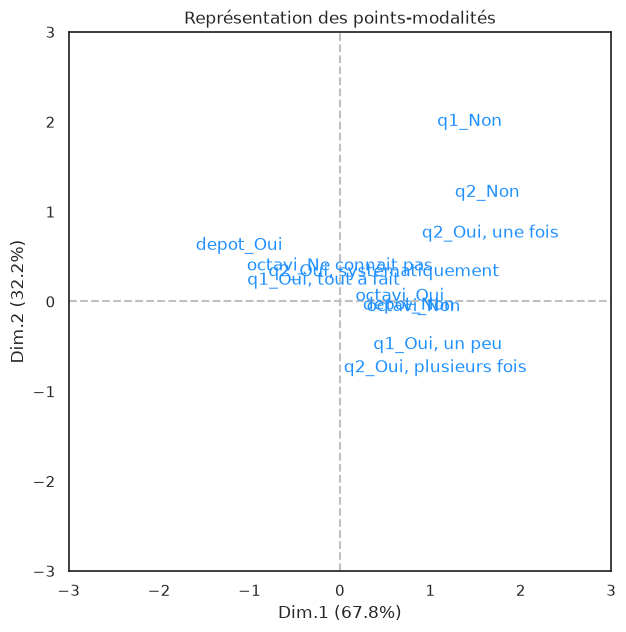

In [253]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(7,7))
ax.axis([-3,+3,-3,+3])
ax.plot([-3,+3],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-3,+3],color='silver',linestyle='--')
ax.set_xlabel("Dim.1 (67.8%)")
ax.set_ylabel("Dim.2 (32.2%)")
plt.title("Représentation des points-modalités")
for i in range(X.shape[1]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],X.columns[i],color='dodgerblue')
plt.show()

In [259]:
contrib12

,index,0,1
0,q1_Non,7.855986,37.624267
1,"q1_Oui, tout à fait",19.426780,0.933328
2,"q1_Oui, un peu",4.281805,12.854885
3,q2_Non,10.968982,13.351169
4,"q2_Oui, plusieurs fois",0.041049,20.926831
5,"q2_Oui, systématiquement",12.490356,2.285348
6,"q2_Oui, une fois",5.574083,4.970738
7,octavi_Ne connait pas,12.883725,2.100409
8,octavi_Non,3.416155,0.660686
9,octavi_Oui,0.156580,0.000433


In [267]:
df_os.columns[:5]

Index(['q1_so_principles', 'q2_hal_depot', 'octavi_depot_rec',
       'depot_entrepot'],
      dtype='object')

In [271]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,:2],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
eta2 = np.zeros((4,2))
#pour chaque facteur
for h in range(2):
    #pour chaque variable
    for j in range(4):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(df_os.iloc[:,j])][h]))/100
#affichage
print(pd.DataFrame(eta2,index=df_os.columns[:],columns=['F1','F2']))


                                  0          1
q1_Non                     7.855986  37.624267
q1_Oui, tout à fait       19.426780   0.933328
q1_Oui, un peu             4.281805  12.854885
q2_Non                    10.968982  13.351169
q2_Oui, plusieurs fois     0.041049  20.926831
q2_Oui, systématiquement  12.490356   2.285348
q2_Oui, une fois           5.574083   4.970738
octavi_Ne connait pas     12.883725   2.100409
octavi_Non                 3.416155   0.660686
octavi_Oui                 0.156580   0.000433
depot_Non                  3.132239   0.586927
depot_Oui                 19.772261   3.704978
                        F1        F2
q1_so_principles  0.555459  0.624717
q2_hal_depot      0.511639  0.504684
octavi_depot_rec  0.289593  0.033556
depot_entrepot    0.403063  0.052151


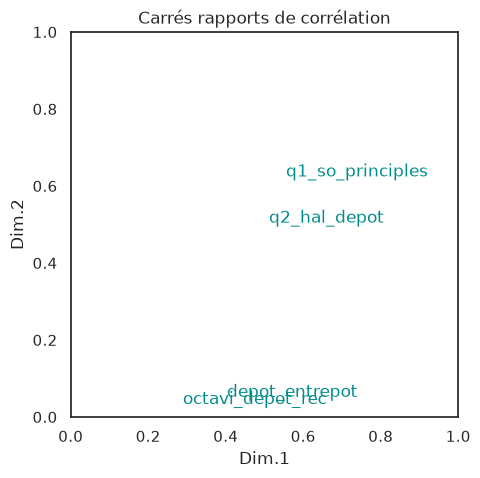

In [274]:
fix,ax = plt.subplots(figsize=(5,5))
ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(4):
    ax.text(eta2[i,0],eta2[i,1],df_os.columns[i],color='darkcyan')
plt.show()